# Check fidelity and plan more simulations

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `ebd964ed89e4`](https://github.com/OJWatson/metis/tree/ebd964ed89e468e4f03197f2c0217c581e294b97).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("ebd964ed89e468e4f03197f2c0217c581e294b97")


Check both the typical prediction and the variability a stochastic surrogate
produces. This example fits a flow-matching model to a small synthetic bank,
then shows its errors, predictive intervals and coverage gaps. For local setup,
see [installation](https://ojwatson.github.io/metis/basics/installing_metis.html).

## Make a stochastic bank

Each run follows $y(t)=(a+u)(1-e^{-t/4})+\epsilon_t$, where the input $a$ ranges
from 0.5 to 2, $u\sim N(0,0.15^2)$ varies between runs, and independent
$\epsilon_t\sim N(0,0.03^2)$ adds observation-scale variation. This simple
simulator gives us repeated trajectories at each input setting.

In [1]:
#| code-fold: true
#| code-summary: "Create the example simulation bank"
import matplotlib.pyplot as plt
import numpy as np
import torch

from metis import (
    SimulationDataset, Surrogate, TrainingConfig,
    assess_coverage, suggest_simulations,
)

torch.set_num_threads(2)
rng = np.random.default_rng(42)
times = np.arange(12)
inputs = np.repeat(np.linspace(0.5, 2.0, 60), 5)[:, None]
curve = 1 - np.exp(-times / 4)
run_effect = rng.normal(0, 0.15, (len(inputs), 1))
outputs = (inputs + run_effect) * curve + rng.normal(0, 0.03, (len(inputs), len(times)))
bank = SimulationDataset.from_arrays(
    inputs, outputs[:, :, None], input_names=["amplitude"],
    output_names=["response"], times=times,
)
split = bank.split(seed=42)
model = Surrogate("flow_matching", model_options={"n_blocks": 1, "embd_dim": 32}).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, eval_every=100, seed=42),
)
print(f"Fitted on {len(split.train)} runs; held out {len(split.test)} test runs")

Fitted on 180 runs; held out 60 test runs


## Measure held-out error and variability

`evaluate` samples 64 trajectories per test input here. Flow matching uses 30
Heun integration steps per draw. Increase these budgets when checking whether
Monte Carlo or solver accuracy affects a result.

In [2]:
report = model.evaluate(split.test, n_samples=64, num_steps=30, solver="heun", seed=42)
report.by_output.to_pandas().round(3)

,output,rmse,mae,predictive_coverage_90,predictive_interval_width_90,crps
0,response,0.117,0.086,0.858,0.344,0.062


- **RMSE / MAE:** error of the sampled mean, in response units.
- **CRPS:** a distribution score; lower is better when comparing the same output.
- **Coverage / width:** how often simulator values fall inside the central 90%
  interval, and how wide that interval is.

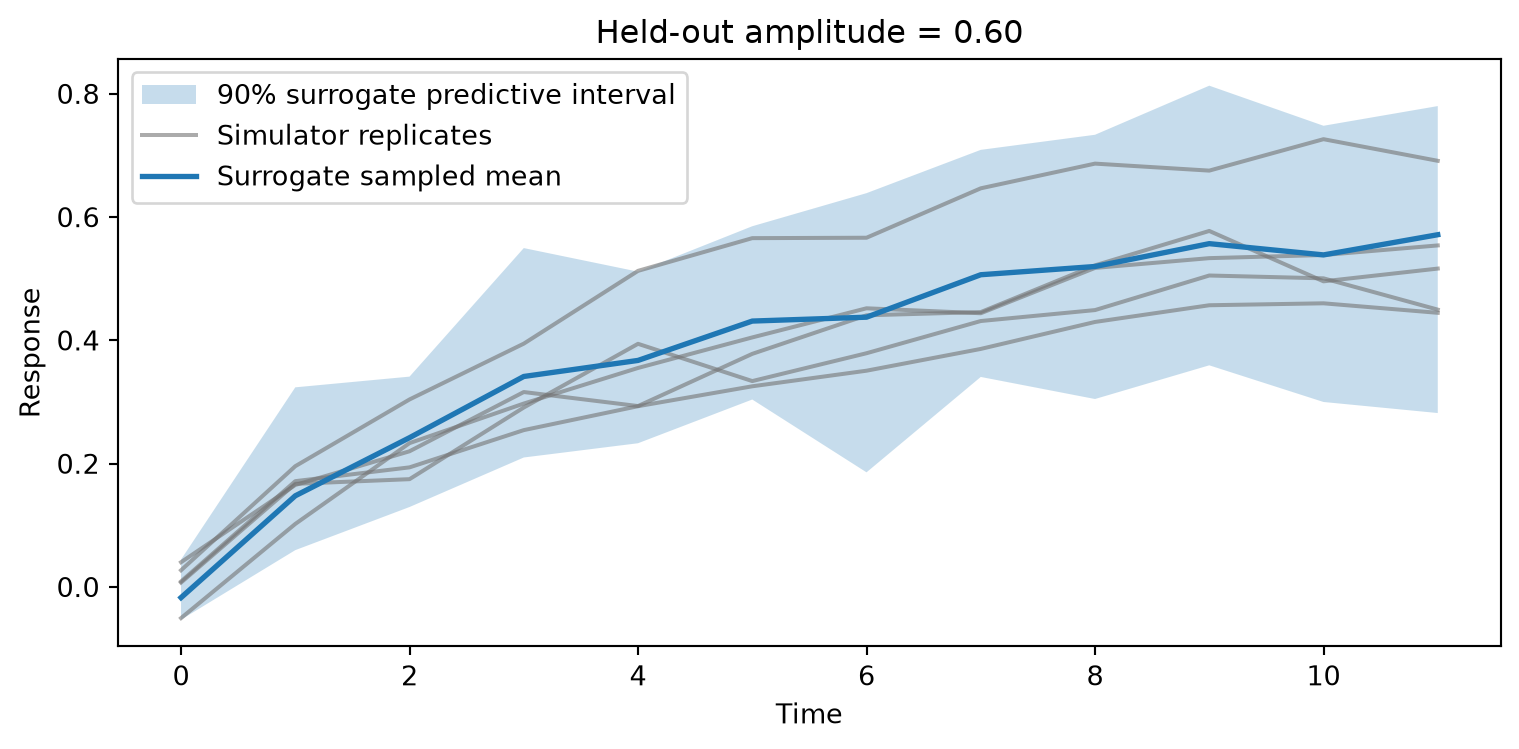

In [3]:
#| label: fig-evaluation-interval
#| fig-cap: 'Flow-matching model fitted to the synthetic response training partition: pointwise 90% predictive intervals and five test simulator replicates at one held-out amplitude.'
group = split.test.group_keys[0]
indices = [i for i, key in enumerate(split.test.group_keys) if key == group]
i = indices[0]
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(times, report.lower[i, :, 0], report.upper[i, :, 0],
                alpha=0.25, label="90% surrogate predictive interval")
for j, index in enumerate(indices):
    ax.plot(times, split.test.outputs[index, :, 0], color="0.45", alpha=0.6,
            label="Simulator replicates" if j == 0 else None)
ax.plot(times, report.predictions[i, :, 0], color="C0", linewidth=2,
        label="Surrogate sampled mean")
ax.set(xlabel="Time", ylabel="Response", title=f"Held-out amplitude = {split.test.inputs[i, 0]:.2f}")
ax.legend()
fig.tight_layout()
plt.show()

*Flow-matching model fitted to the synthetic response training partition: pointwise 90% predictive intervals and five test simulator replicates at one held-out amplitude.*

These bands describe the fitted generator's variability. They are **not**
confidence intervals for surrogate accuracy or simultaneous bands for an entire
trajectory. Low coverage, very wide intervals or implausible paths need further
investigation, even if mean error looks small.

## Find difficult input settings

In [4]:
report.worst_groups(5).to_pandas().round(3)

,group,n_replicates,rmse,mae,replicate_mean_rmse,input:amplitude
0,[1.7457627118644068],5,0.192,0.158,0.028,1.746
1,[1.7203389830508475],5,0.165,0.134,0.057,1.720
2,[1.8728813559322035],5,0.147,0.107,0.085,1.873
3,[1.440677966101695],5,0.141,0.117,0.027,1.441
4,[1.288135593220339],5,0.121,0.093,0.035,1.288


Inspect errors by parameter setting and by output, rather than relying on one
aggregate score. For scientific models, also check quantities such as peak
height, peak time or conserved totals. METIS supports explicit nonnegative,
nondecreasing and conserved-total checks through `evaluate(constraints=...)`;
see the [API](https://ojwatson.github.io/metis/package/api.html).

## Suggest new parameter settings

Supply candidates that your simulator can validly run. METIS can find gaps in
input coverage; it does not infer where the surrogate's error is highest.

In [5]:
candidates = np.linspace(0.5, 2.0, 200)[:, None]
coverage = assess_coverage(split.train, candidates)
suggestions = suggest_simulations(split.train, candidates, n=5)
suggestions.select("amplitude", "priority", "selection_distance").to_pandas().round(3)

,amplitude,priority,selection_distance
0,1.744,1,0.033
1,1.209,2,0.032
2,0.945,3,0.026
3,1.887,4,0.025
4,0.613,5,0.025


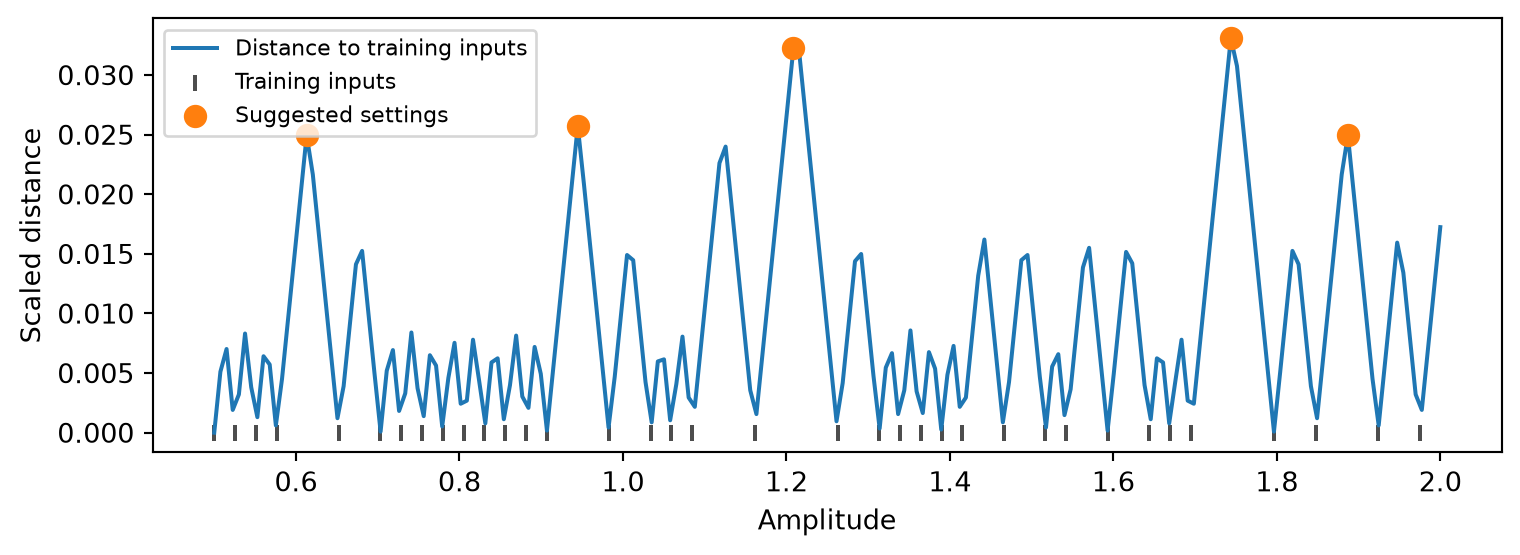

In [6]:
#| label: fig-evaluation-coverage
#| fig-cap: 'Synthetic response training partition: distance to the nearest fitted input, scaled by the training input range. Suggested points fill coverage gaps, without using surrogate errors.'
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(coverage["amplitude"], coverage["nearest_training_distance"], label="Distance to training inputs")
ax.scatter(np.unique(split.train.inputs), np.zeros(len(np.unique(split.train.inputs))),
           marker="|", color="0.3", label="Training inputs")
ax.scatter(suggestions["amplitude"], suggestions["nearest_training_distance"],
           color="C1", s=60, label="Suggested settings", zorder=3)
ax.set(xlabel="Amplitude", ylabel="Scaled distance")
ax.legend(fontsize="small")
fig.tight_layout()
plt.show()

*Synthetic response training partition: distance to the nearest fitted input, scaled by the training input range. Suggested points fill coverage gaps, without using surrogate errors.*

If test errors guide new simulations or tuning, reserve a fresh independent test
bank for the next final assessment. Save a report with `report.save(...)`;
`report.metadata` records the model, data fingerprints and evaluation settings.